# Association Rule Mining for Food Product Bundles

**DS-A38 | Muhammad Usman Nazir | 24PWDSC0178**

This notebook compares Apriori and FP-Growth. The bundled 20-basket file is an illustrative starter sample, not Dunnhumby data. Replace `DATA_PATH` with a prepared Dunnhumby basket-item CSV (`basket_id,product_name`) before final submission. See README for provenance and preparation notes.

## 1. Imports and configuration
Set the thresholds once so both algorithms are compared fairly.

In [1]:
from pathlib import Path
import time
import pandas as pd
import matplotlib.pyplot as plt
from src.apriori import load_transactions, encode_transactions, mine_rules

DATA_PATH = 'data/groceries.csv'  # Replace with prepared Dunnhumby basket-item CSV
MIN_SUPPORT = 0.05
MIN_CONFIDENCE = 0.30
MIN_LIFT = 1.0
OUT = Path('output')
OUT.mkdir(exist_ok=True)

## 2. Load and prepare baskets
A basket is one set of distinct products. Transaction encoding converts baskets to a boolean matrix for itemset mining. The loader accepts a wide transaction file or normalized `basket_id,product_name` rows.

In [2]:
transactions = load_transactions(DATA_PATH)
encoded = encode_transactions(transactions)
basket_sizes = pd.Series([len(set(t)) for t in transactions], name='items_per_basket')
summary = pd.Series({'transactions': len(transactions), 'distinct_products': encoded.shape[1], 'average_basket_size': basket_sizes.mean(), 'median_basket_size': basket_sizes.median()})
summary

transactions           20.00
distinct_products       4.00
average_basket_size     2.55
median_basket_size      2.00
dtype: float64

## 3. Data checks and exploratory analysis
Empty baskets are excluded by the loader and repeated products collapse during one-hot encoding. The example has no customer or date fields, so customer-level or seasonal analysis is not possible. Perform those checks on the downloaded source tables and document any join or filtering choices.

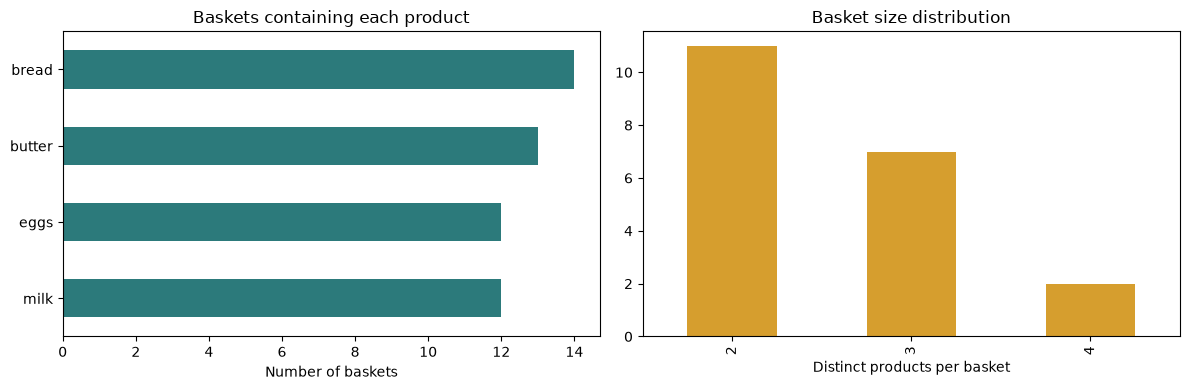

In [3]:
product_counts = encoded.sum().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
product_counts.sort_values().plot.barh(ax=axes[0], color='#2c7a7b', title='Baskets containing each product')
basket_sizes.value_counts().sort_index().plot.bar(ax=axes[1], color='#d69e2e', title='Basket size distribution')
axes[0].set_xlabel('Number of baskets'); axes[1].set_xlabel('Distinct products per basket')
plt.tight_layout()

## 4. Apriori and FP-Growth
Both algorithms use the same support threshold. Apriori generates and tests candidate itemsets level by level. FP-Growth compresses transactions into an FP-tree and mines patterns without explicit candidate generation. On this tiny dataset, elapsed time is not a meaningful scalability comparison.

In [4]:
results = {}
for algorithm in ('apriori', 'fpgrowth'):
    start = time.perf_counter()
    itemsets, rules = mine_rules(encoded, algorithm, MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT)
    elapsed = time.perf_counter() - start
    results[algorithm] = (itemsets, rules, elapsed)
    print(f'{algorithm}: {len(itemsets)} frequent itemsets, {len(rules)} rules, {elapsed:.6f} seconds')

apriori: 15 frequent itemsets, 5 rules, 0.020672 seconds
fpgrowth: 15 frequent itemsets, 5 rules, 0.018122 seconds


## 5. Results and metric interpretation
Support is the share of all baskets containing the rule's union. Confidence is the share of antecedent baskets that also contain the consequent. Lift divides confidence by the consequent's baseline support. Confidence alone can look strong simply because the consequent is popular; lift near 1 indicates little association beyond that baseline. Filter and rank using all three measures, and avoid overinterpreting rare rules.

In [5]:
apriori_itemsets, apriori_rules, _ = results['apriori']
fpgrowth_itemsets, fpgrowth_rules, _ = results['fpgrowth']
# Confirm matching itemsets and rule metrics under identical settings
left = set((round(r.support, 12), tuple(sorted(r.itemsets))) for r in apriori_itemsets.itertuples())
right = set((round(r.support, 12), tuple(sorted(r.itemsets))) for r in fpgrowth_itemsets.itertuples())
print('Frequent itemsets match:', left == right)
print('Rule counts match:', len(apriori_rules) == len(fpgrowth_rules))
apriori_rules[['antecedents','consequents','support','confidence','lift']].head(10)

Frequent itemsets match: True
Rule counts match: True


,antecedents,consequents,support,confidence,lift
0,"bread, eggs",butter,0.25,0.714286,1.098901
1,butter,"bread, eggs",0.25,0.384615,1.098901
2,eggs,butter,0.40,0.666667,1.025641
3,butter,eggs,0.40,0.615385,1.025641
4,"bread, eggs, milk",butter,0.10,0.666667,1.025641


## 6. Limitations and bundle suggestions
The bundled sample has only 20 baskets and cannot support reliable business decisions. Rules suggest co-occurrence, not causation or incremental sales. Bundle suggestions should be reconsidered after running the actual Dunnhumby data, checking adequate support, promotions, seasonality, margin, stock, and whether the products make practical sense. Record the chosen sample/time range and cite the original dataset.

In [6]:
# Save tables to accompany the report
OUT.mkdir(exist_ok=True)
for algorithm, (itemsets, rules, elapsed) in results.items():
    itemsets.to_csv(OUT / f'{algorithm}_frequent_itemsets.csv', index=False)
    rules.to_csv(OUT / f'{algorithm}_rules.csv', index=False)
pd.DataFrame([{'algorithm': a, 'frequent_itemsets': len(v[0]), 'rules': len(v[1]), 'runtime_seconds': v[2]} for a,v in results.items()]).to_csv(OUT / 'algorithm_comparison.csv', index=False)
print('Saved result tables in', OUT.resolve())

Saved result tables in D:\Projects\Association_Rule_Mining_For_Food_Product_Bundies\output
